# UMAP: o batch effect domina?

Cada painel destaca uma categoria (azul) sobre o resto (cinza). Doze MoAs ou dez semanas não dão para separar por cor num único scatter. Cada ponto é uma imagem. O UMAP é só para olhar: os números abaixo das figuras são calculados nos embeddings originais, por tratamento.

C:\Users\Pichau\projetos\cell-moa\cell-moa\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


C:\Users\Pichau\projetos\cell-moa\cell-moa\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


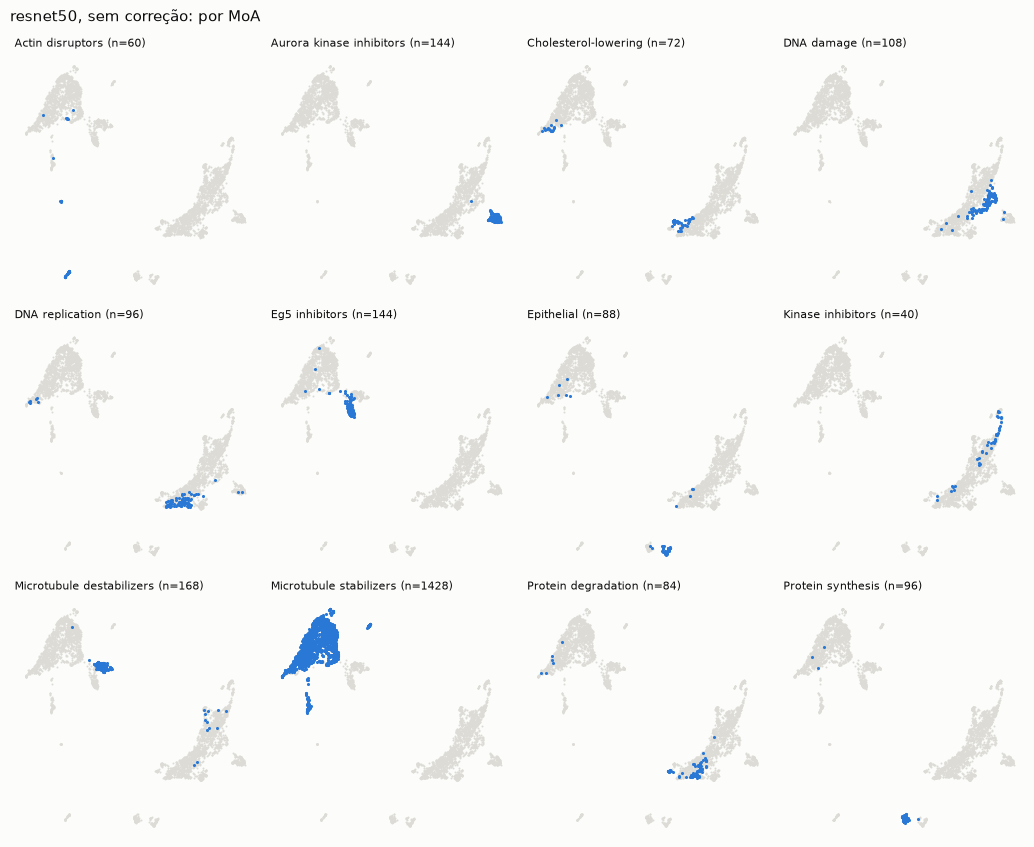

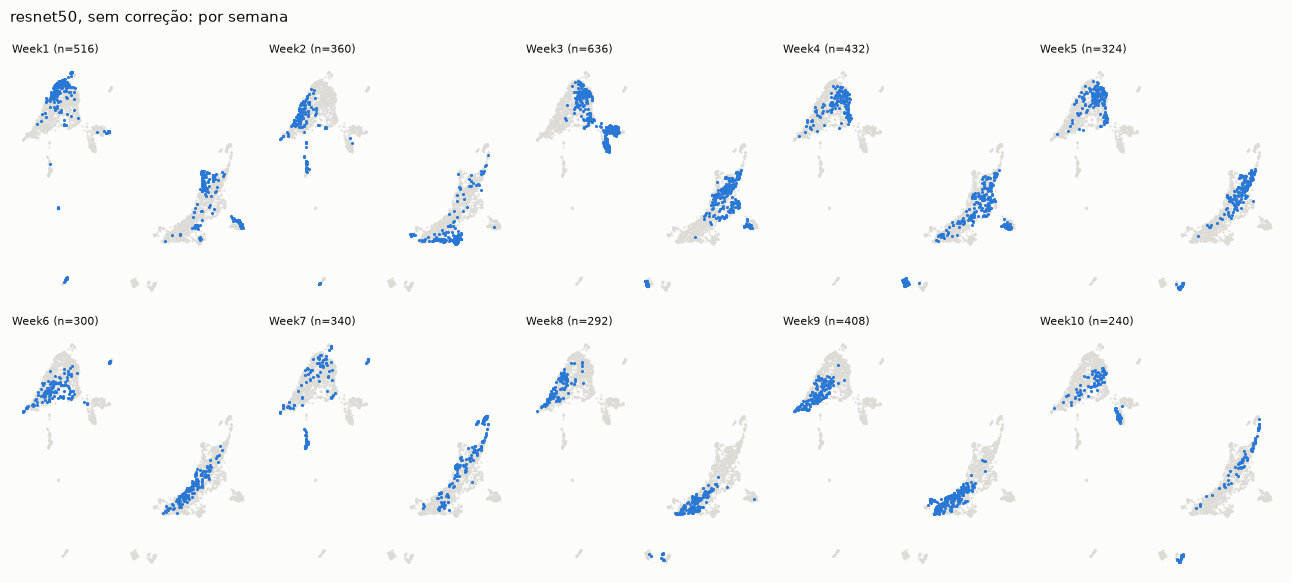

C:\Users\Pichau\projetos\cell-moa\cell-moa\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


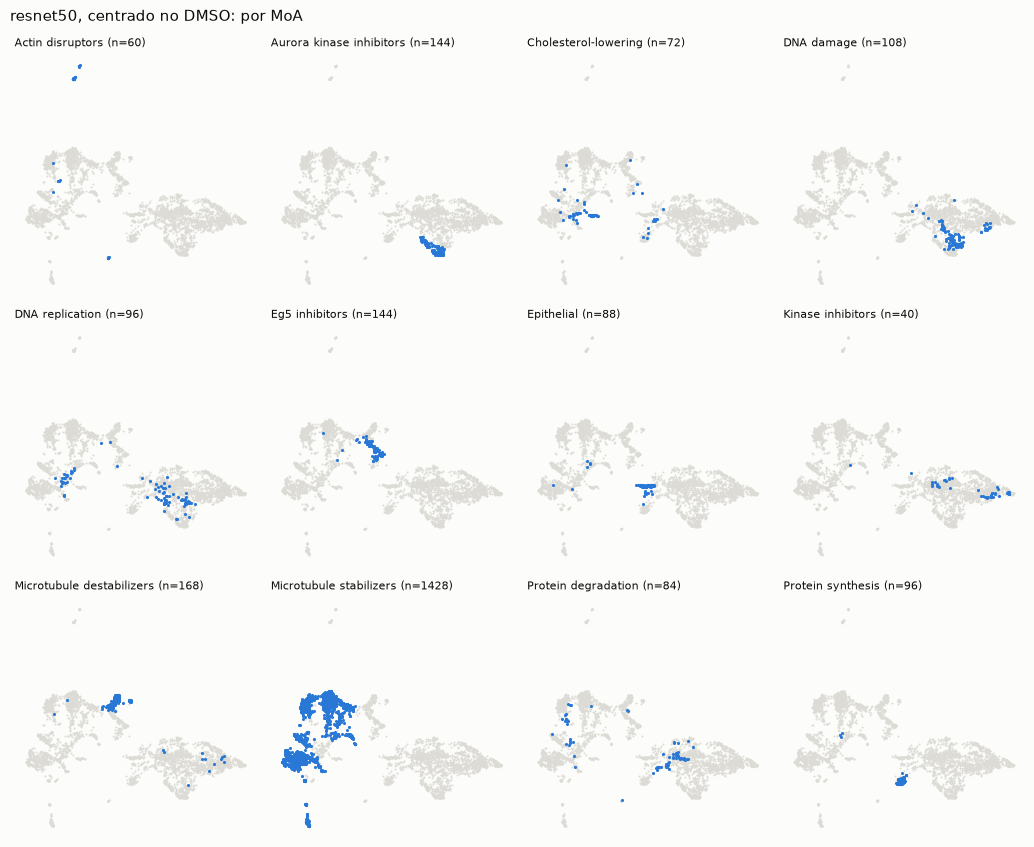

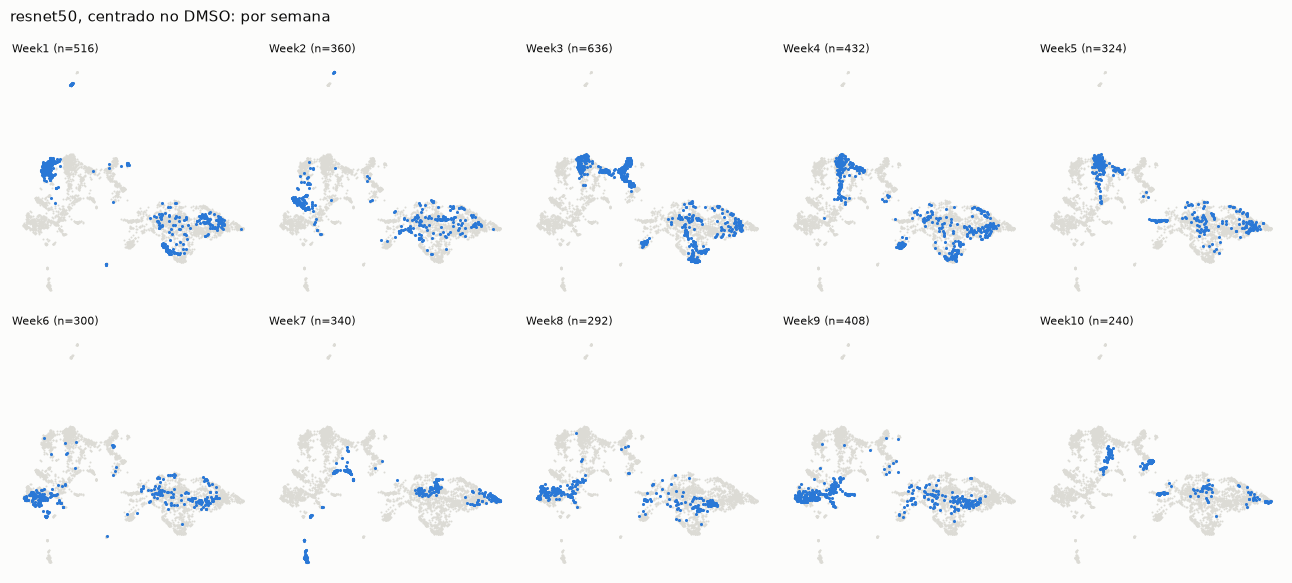

C:\Users\Pichau\projetos\cell-moa\cell-moa\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


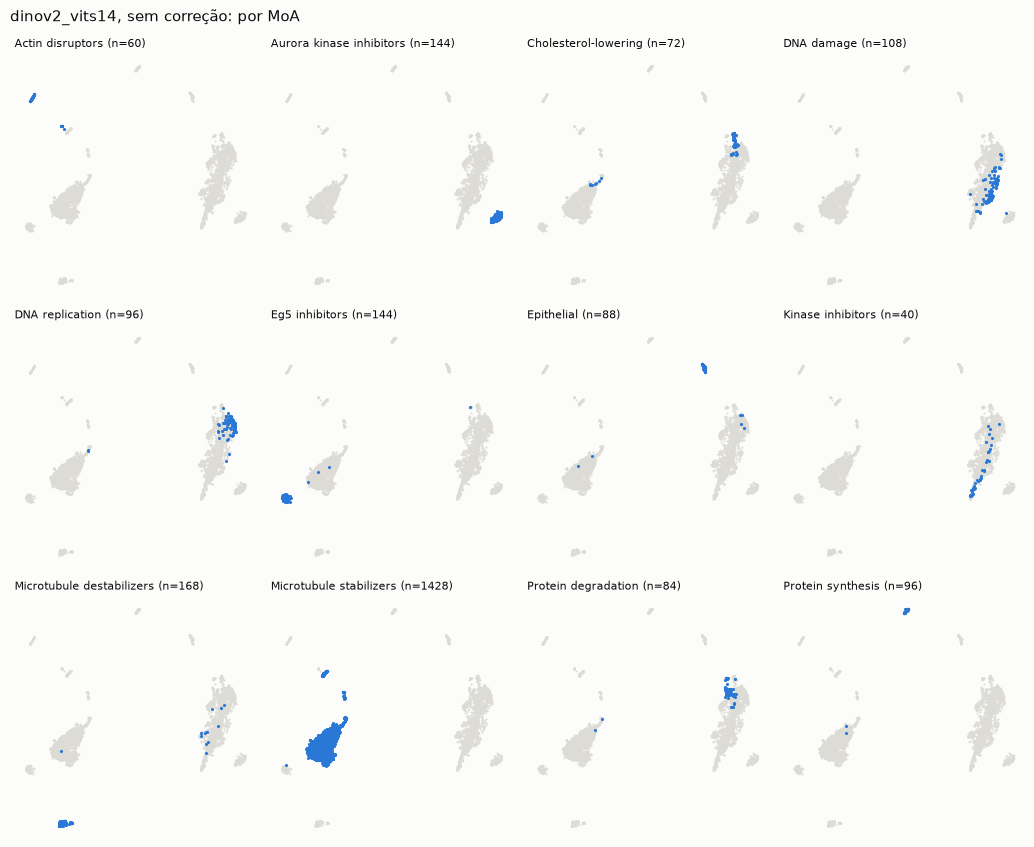

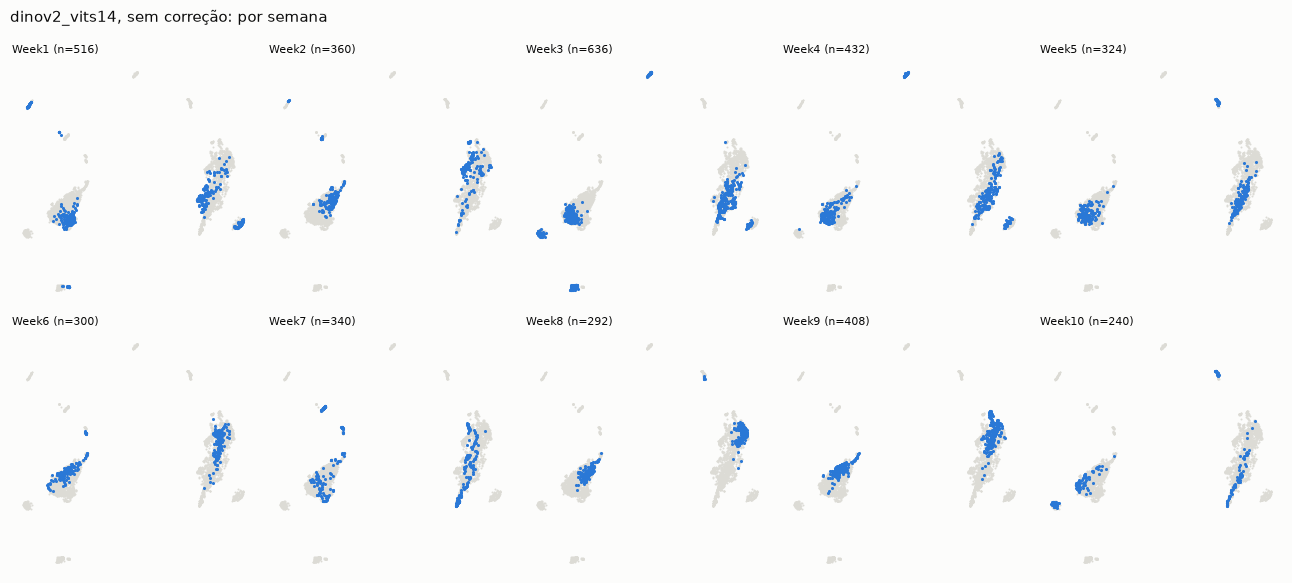

C:\Users\Pichau\projetos\cell-moa\cell-moa\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


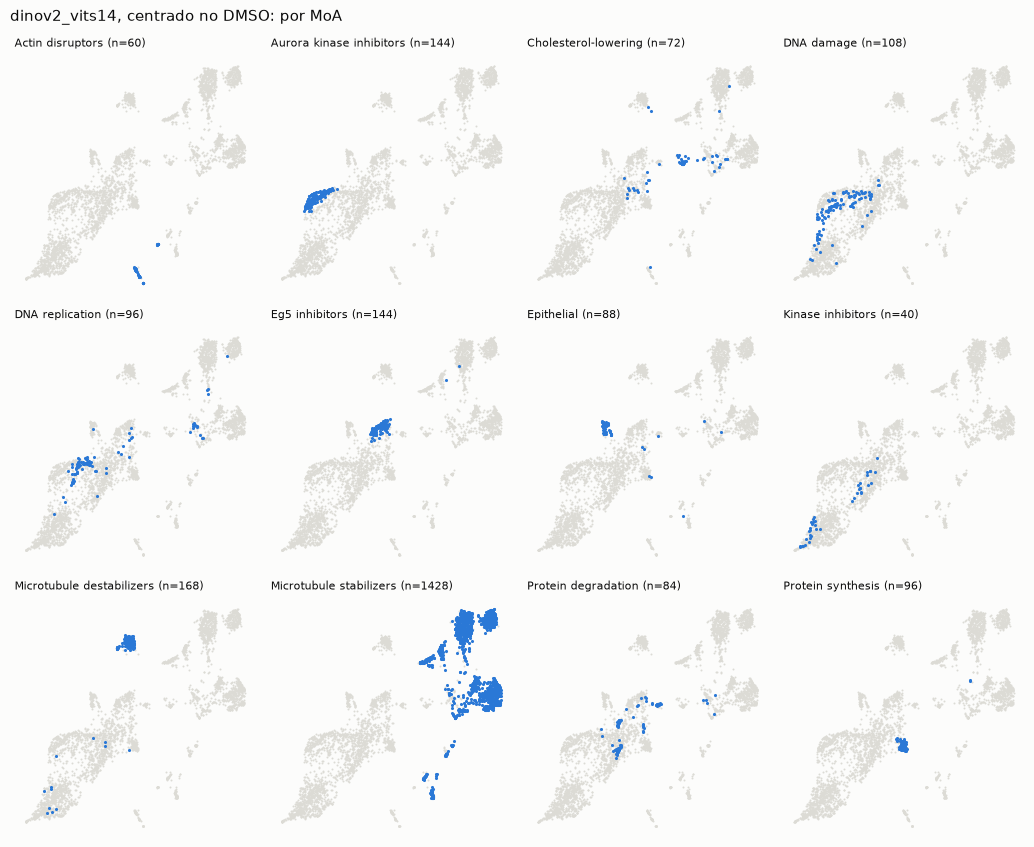

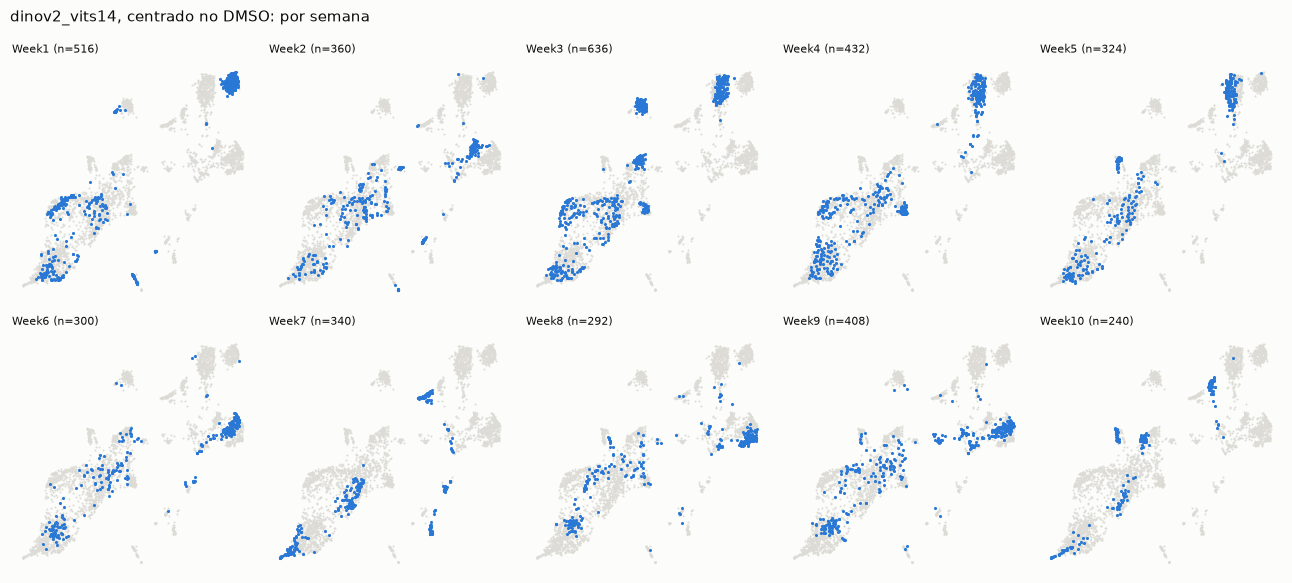

,backbone,correcao,vizinho_mesma_semana,vizinho_mesma_semana_acaso,silhouette_moa,silhouette_semana
0,resnet50,sem correção,0.366071,0.123693,0.353190,-0.103967
1,resnet50,centrado no DMSO,0.473214,0.123693,0.236984,-0.122936
2,dinov2_vits14,sem correção,0.366071,0.123693,0.425431,-0.147702
3,dinov2_vits14,centrado no DMSO,0.437500,0.123693,0.321394,-0.126446


In [1]:
import os
import sys
from pathlib import Path

if Path.cwd().name == 'notebooks':
    os.chdir('..')
sys.path.insert(0, str(Path.cwd()))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import umap
from sklearn.metrics import silhouette_score

from cellvs.evaluate import aggregate, center_on_dmso, matches

meta = pd.read_csv('data/metadata.csv')
BACKBONES = ['resnet50', 'dinov2_vits14']
SURFACE, TEXT, HIGHLIGHT, OTHER = '#fcfcfb', '#0b0b0b', '#2a78d6', '#dcdbd5'


def facets(xy, labels, cats, title, path, ncols):
    nrows = int(np.ceil(len(cats) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.6 * ncols, 2.7 * nrows + 0.5), facecolor=SURFACE)
    for ax in axes.flat:
        ax.axis('off')
    for ax, c in zip(axes.flat, cats):
        on = labels == c
        ax.scatter(*xy[~on].T, s=2, c=OTHER, linewidths=0, rasterized=True)
        ax.scatter(*xy[on].T, s=5, c=HIGHLIGHT, linewidths=0, rasterized=True)
        ax.set_title(f'{c} (n={on.sum()})', fontsize=8, color=TEXT, loc='left')
    fig.suptitle(title, fontsize=11, color=TEXT, x=0.01, ha='left')
    fig.tight_layout()
    fig.savefig(path, dpi=130)
    plt.show()


moas = sorted(meta.moa.dropna().unique())
weeks = sorted(meta.batch.unique(), key=lambda w: int(w[4:]))
summary = []

for b in BACKBONES:
    raw = np.load(f'results/emb_{b}.npy')
    assert len(raw) == len(meta)
    for name, emb in [('sem correção', raw), ('centrado no DMSO', center_on_dmso(raw, meta))]:
        tag = f"{b}_{'raw' if name == 'sem correção' else 'centered'}"
        xy = umap.UMAP(metric='cosine', random_state=0).fit_transform(emb)
        facets(xy, meta.moa.fillna('DMSO').values, moas, f'{b}, {name}: por MoA', f'results/umap_{tag}_moa.png', 4)
        facets(xy, meta.batch.values, weeks, f'{b}, {name}: por semana', f'results/umap_{tag}_batch.png', 5)

        t_emb, t = aggregate(emb, meta)
        keep = ((t.compound != 'DMSO') & t.moa.notna()).values
        t_emb, t = t_emb[keep], t[keep].reset_index(drop=True)
        m = matches(t_emb, t, exclude_batch=False)
        same_batch = (t.batch.values[m.i] == t.batch.values[m.j]).mean()
        pool = [(t.batch.values[t.compound.values != t.compound[i]] == t.batch[i]).mean() for i in m.i]
        summary.append({
            'backbone': b, 'correcao': name,
            'vizinho_mesma_semana': same_batch,
            'vizinho_mesma_semana_acaso': np.mean(pool),
            'silhouette_moa': silhouette_score(t_emb, t.moa, metric='cosine'),
            'silhouette_semana': silhouette_score(t_emb, t.batch, metric='cosine'),
        })

summary = pd.DataFrame(summary)
summary.to_csv('results/batch_vs_moa.csv', index=False)
summary